# ♟️ Chess Match Predictor — Análisis Exploratorio

Este notebook realiza un análisis exploratorio del dataset de partidas de ajedrez construido a partir de la API de Chess.com.

**Antes de ejecutar este notebook**, asegúrate de haber generado el dataset:
```bash
python -m src.data_collection
```

## 1. Importaciones y configuración

In [1]:
import sys
import os

# Add project root to path
sys.path.insert(0, os.path.join(os.getcwd(), '..'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.exploratory_analysis import ExploratoryAnalyzer

# Inline plots
%matplotlib inline
plt.rcParams['figure.dpi'] = 100

print('Imports OK')

Imports OK


## 2. Carga del dataset

In [2]:
DATA_PATH = os.path.join('..', 'data', 'processed', 'dataset.csv')

if not os.path.exists(DATA_PATH):
    print(f'Dataset no encontrado en {DATA_PATH}')
    print('Ejecuta: python -m src.data_collection')
else:
    df = pd.read_csv(DATA_PATH)
    print(f'Dataset cargado: {df.shape[0]} filas, {df.shape[1]} columnas')
    display(df.head())

Dataset cargado: 65778 filas, 10 columnas


,white_rating,black_rating,rating_diff,abs_rating_diff,time_class_encoded,rated,base_time,increment,target,termination_reason
0,1708,1608,100,100,3,1,259200,0,0,checkmated
1,1726,1577,149,149,3,1,172800,0,0,resigned
2,1727,842,885,885,3,1,172800,0,0,resigned
3,819,1727,-908,908,3,1,172800,0,1,checkmated
4,1729,1116,613,613,3,1,172800,0,0,resigned


## 3. Estadísticas descriptivas

In [3]:
display(df.describe())
print('\nValores nulos por columna:')
display(df.isnull().sum())

,white_rating,black_rating,rating_diff,abs_rating_diff,time_class_encoded,rated,base_time,increment,target
count,65778.000000,65778.000000,65778.000000,65778.000000,65778.000000,65778.000000,6.577800e+04,65778.000000,65778.000000
mean,1250.380005,1249.856745,0.523260,79.931299,0.914987,0.973578,9.908027e+03,0.446912,0.536547
std,403.234397,402.768626,156.682374,134.761012,0.800355,0.160388,7.721330e+04,1.839845,0.564394
min,100.000000,100.000000,-2048.000000,0.000000,0.000000,0.000000,1.000000e+01,0.000000,0.000000
25%,980.000000,980.000000,-38.000000,18.000000,0.000000,1.000000,6.000000e+01,0.000000,0.000000
50%,1254.000000,1254.000000,0.000000,39.000000,1.000000,1.000000,1.800000e+02,0.000000,1.000000
75%,1525.000000,1524.000000,39.000000,80.000000,1.000000,1.000000,6.000000e+02,0.000000,1.000000
max,3172.000000,3172.000000,2048.000000,2048.000000,3.000000,1.000000,1.209600e+06,60.000000,2.000000



Valores nulos por columna:


white_rating          0
black_rating          0
rating_diff           0
abs_rating_diff       0
time_class_encoded    0
rated                 0
base_time             0
increment             0
target                0
termination_reason    0
dtype: int64

## 4. Distribución de resultados

Analizamos cómo se distribuyen las tres clases: Victoria A (0), Victoria B (1), Empate (2).

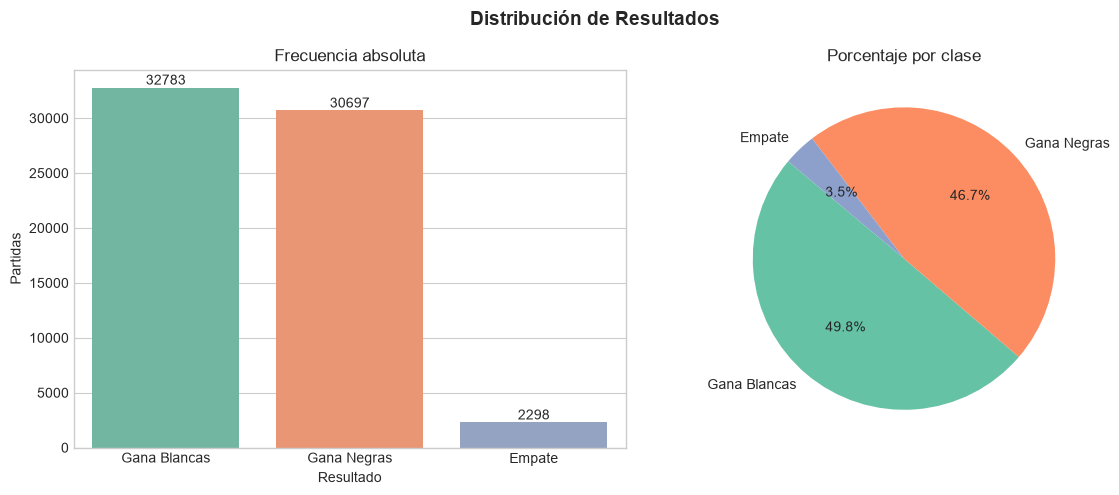

In [4]:
analyzer = ExploratoryAnalyzer()
fig = analyzer.plot_result_distribution(df)
plt.show()

## 5. Distribución de ratings

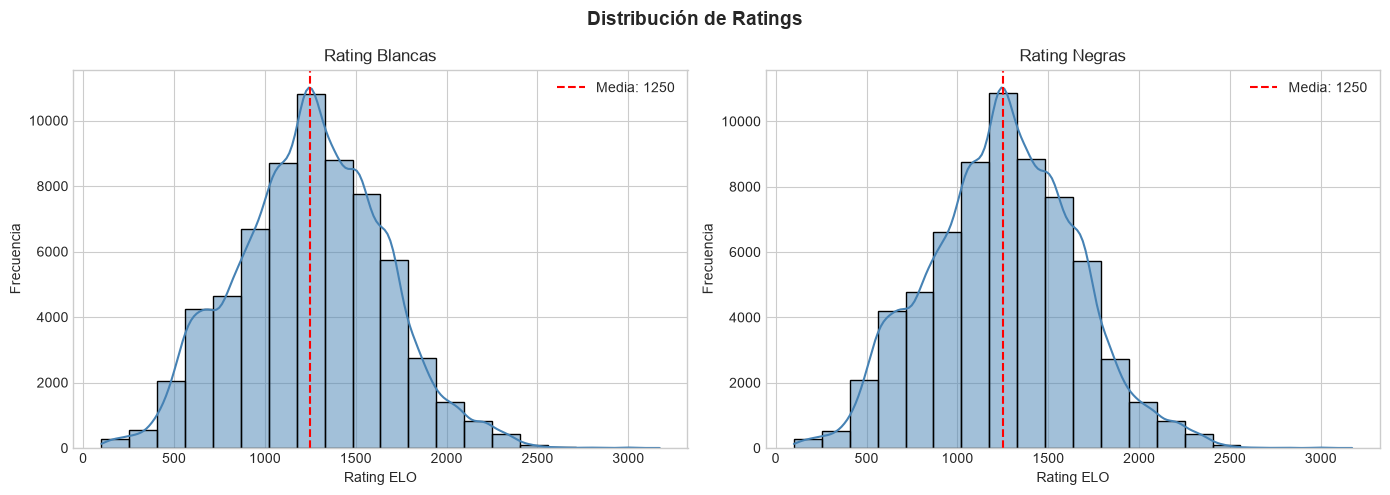

In [5]:
fig = analyzer.plot_rating_distribution(df)
plt.show()

## 6. Diferencia de rating vs resultado

¿Cuánto influye la ventaja en el rating en el resultado final?

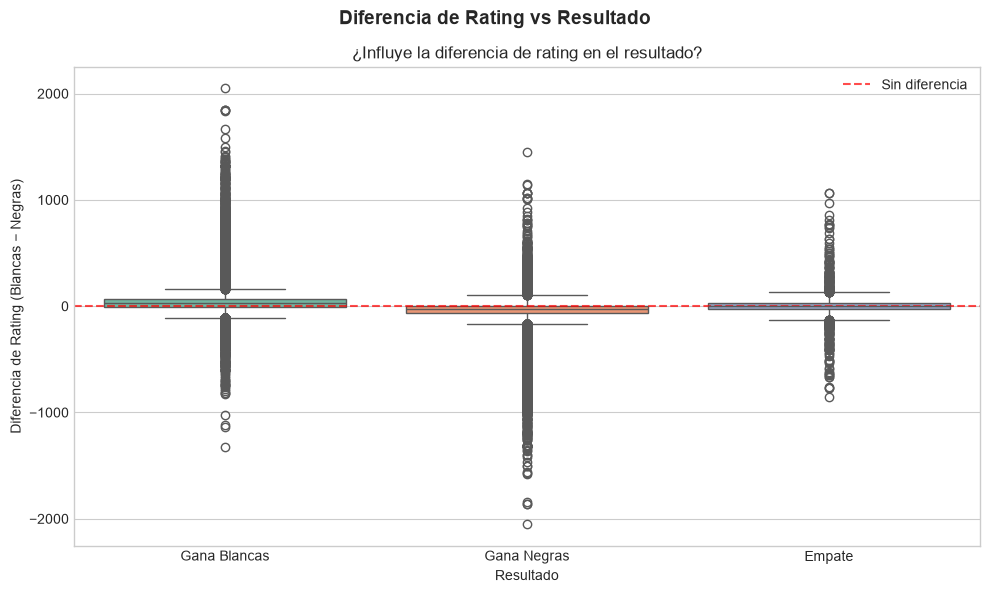

In [6]:
fig = analyzer.plot_rating_diff_vs_result(df)
plt.show()

## 7. Ventaja de las blancas

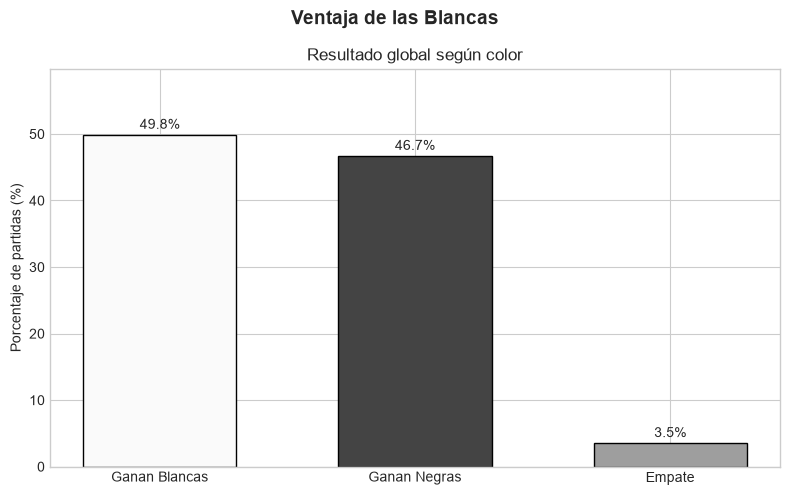

In [7]:
fig = analyzer.plot_white_advantage(df)
plt.show()

## 8. Comparación por ritmo de juego

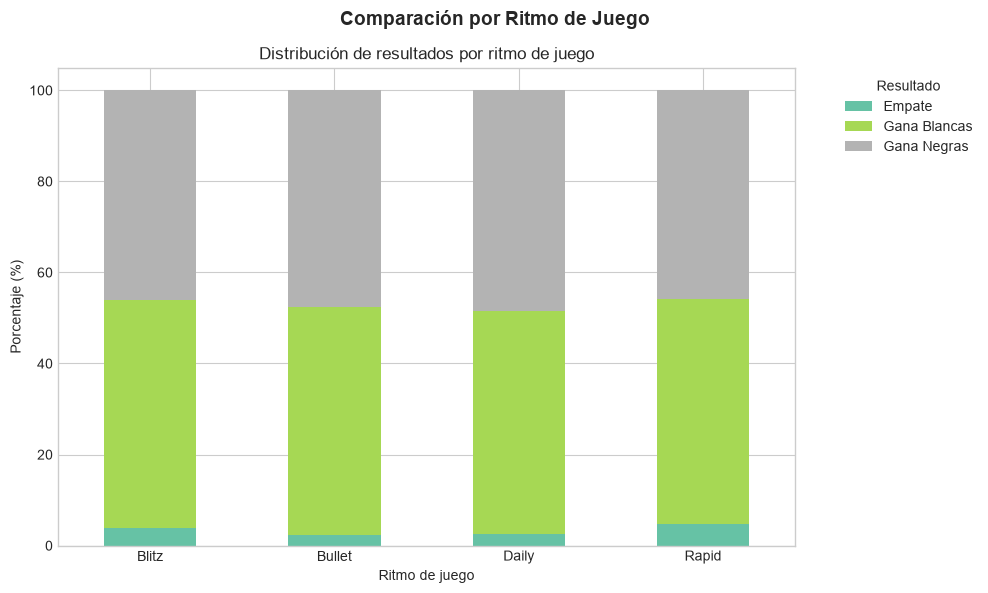

In [8]:
fig = analyzer.plot_time_class_comparison(df)
plt.show()

## 9. Matriz de correlaciones

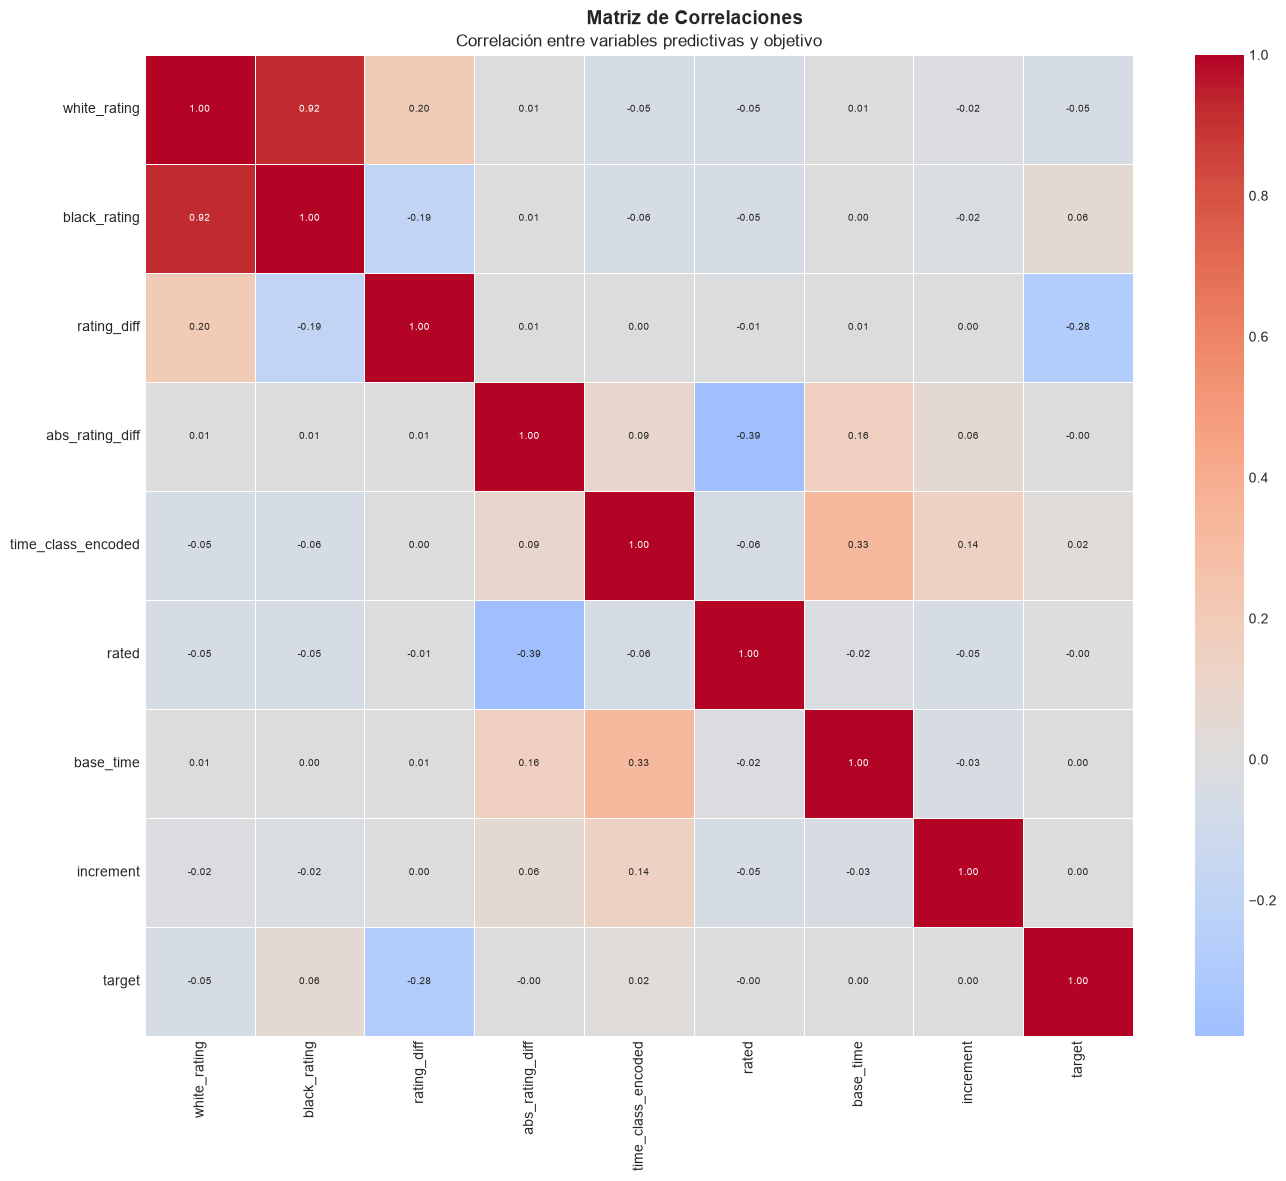

In [9]:
fig = analyzer.plot_correlation_matrix(df)
plt.show()

## 10. Distribución de todas las variables

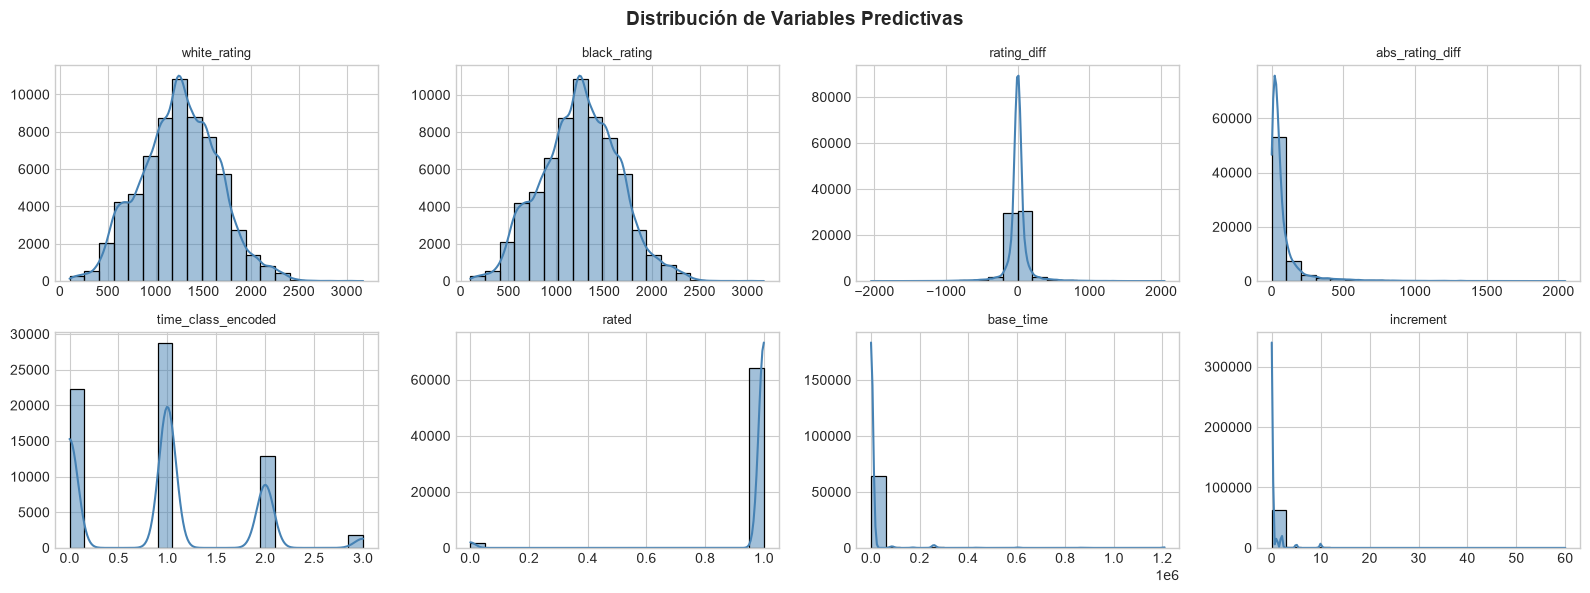

In [10]:
fig = analyzer.plot_feature_distributions(df)
plt.show()

## 11. Conclusiones automáticas

In [11]:
conclusions = analyzer._generate_conclusions(df)
for i, c in enumerate(conclusions, 1):
    print(f'{i}. {c}\n')

1. Distribución de resultados: Gana Blancas 49.8%, Gana Negras 46.7%, Empate 3.5%. Distribución relativamente balanceada.

2. Cuando ganan las blancas, la diferencia de rating media (blancas − negras) es 50. Cuando ganan las negras, es -53. Esto confirma que el rating es un predictor relevante.

3. Las blancas ganan el 49.8% de las partidas frente al 46.7% de las negras. La ventaja de las blancas es visible en este dataset.



## 12. Generación completa del informe

Guarda todos los gráficos en `data/processed/`.

In [12]:
output_dir = os.path.join('..', 'data', 'processed')
report = analyzer.generate_full_report(df, output_dir)

print('Gráficos guardados:')
for name, path in report['plots'].items():
    print(f'  {name}: {path}')

print('\nConclusiones:')
for c in report['conclusions']:
    print(f'  - {c}')

Gráficos guardados:
  result_distribution: ..\data\processed\result_distribution.png
  rating_distribution: ..\data\processed\rating_distribution.png
  rating_diff_vs_result: ..\data\processed\rating_diff_vs_result.png
  white_advantage: ..\data\processed\white_advantage.png
  time_class_comparison: ..\data\processed\time_class_comparison.png
  correlation_matrix: ..\data\processed\correlation_matrix.png
  feature_distributions: ..\data\processed\feature_distributions.png

Conclusiones:
  - Distribución de resultados: Gana Blancas 49.8%, Gana Negras 46.7%, Empate 3.5%. Distribución relativamente balanceada.
  - Cuando ganan las blancas, la diferencia de rating media (blancas − negras) es 50. Cuando ganan las negras, es -53. Esto confirma que el rating es un predictor relevante.
  - Las blancas ganan el 49.8% de las partidas frente al 46.7% de las negras. La ventaja de las blancas es visible en este dataset.
